## Initial Spinup Analysis: 
Comparison of model output to forcing to ensure everything is working as expected.

This hourly version looks at a small portion of model output and doesn't consider Julian vs Gregorian dates. All model runs should start after 1901.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import os

In [2]:
# Run configuration
snotel_site = 'Elk Cabin'  #Use the Snotel name
spin_up = '50y'
forcings = 's00000000'
forcing_version = 'v0.4.4'  # Version of the forcing data
spinup_version = 'v0.3debug'
path_env = 'desktop' # 'desktop' or 'alpine'

In [3]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    forcing_path = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
    forcing_path = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [4]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
print(f'Output site: {site}')

Output site: elkcabin


Load forcing:
Forcing is 10 years of NLDAS data that is then looped for the spinup period.

In [5]:
forcing_10yr = xr.open_dataset(os.path.join(forcing_path, site, f'{site}_spinup_s00000000_{forcing_version}.nc'))

In [6]:
forcing_10yr

<xarray.Dataset> Size: 6MB
Dimensions:           (latitude: 1, longitude: 1, time: 87672)
Coordinates:
  * latitude          (latitude) float64 8B 35.7
  * longitude         (longitude) float64 8B -105.8
  * time              (time) object 701kB 1986-10-09 00:00:00 ... 1996-10-08 ...
Data variables:
    Tair              (time, latitude, longitude) float64 701kB ...
    Qair              (time, latitude, longitude) float64 701kB ...
    Psurf             (time, latitude, longitude) float64 701kB ...
    Rainf             (time, latitude, longitude) float64 701kB ...
    Snowf             (time, latitude, longitude) float64 701kB ...
    SWdown            (time, latitude, longitude) float64 701kB ...
    LWdown            (time, latitude, longitude) float64 701kB ...
    Wind              (time, latitude, longitude) float64 701kB ...
    reference_height  (latitude, longitude) int64 8B ...
    canopy_height     (latitude, longitude) float64 8B ...

In [ ]:
def get_spinup_forcing(forcing_ds: xr.Dataset, var_name: str) -> pd.Series:
    '''
    Extract a given variable (at a daily timestep) from the forcing dataset and loop it for the 100 year spinup period.
    Return a pandas Series with the looped data.
    '''
    # If 'precip' get sum of 'Rainf' and 'Snowf'
    if var_name == 'precip':
        forcing_ds = forcing_ds.assign(precip=forcing_ds['Rainf'] + forcing_ds['Snowf'])
    
    # Extract the variable data
    var_df = forcing_ds[var_name].isel(latitude=0, longitude=0).to_dataframe()
    data = var_df[var_name] # Extract the variable column
    data.index = data.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900

    # Resample to daily frequency
    data_daily = data.resample('D').mean()

    # Loop the data for the spinup period
    spinup_years = int(spin_up[:-1])  # Extract the number of years from the spin_up string
    model_start_year = data_daily.index[-1].year - spinup_years
    model_start = data_daily.index[0].replace(year=model_start_year)

    # Create date range accounting for Julian 1900 leap year if necessary
    if model_start < pd.Timestamp('1900-03-01'):
        model_end = data_daily.index[-1] + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
    else:
        model_end = data_daily.index[-1]
    model_index = pd.date_range(start=model_start, end=model_end, freq='D')

    # Loop the data to fill the spinup period, using 1 extra concatenation to ensure full coverage
    looped = pd.concat([data_daily] * int(spinup_years / 10 + 1), ignore_index=True)
    
    # Ensure the looped data matches the model index length
    looped_values = looped[:len(model_index)].values

    # Shift index by 12 hours to match model output
    model_index = model_index + pd.Timedelta(hours=12)

    output = pd.Series(looped_values, index=model_index)
    output.name = var_name

    return output
    


In [ ]:
# Verify the function works for Tair
# test = get_spinup_forcing(forcing_10yr, 'Tair')
# test2 = forcing_10yr['Tair'].isel(latitude=0, longitude=0).to_series()
# test2.index = test2.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900
# test2 = test2.resample('D').mean()

Load diagnostics

In [7]:
output_folder = os.path.join(output_path,f'{site}/{site}_spinup_{spin_up}_{forcings}_{spinup_version}/history/')

In [8]:
# Specify diagnostics name
diag_name = 'land_hourly'

In [9]:
# Find the land daily file name in folder and open
diag=None
for filename in os.listdir(output_folder):
    if filename.endswith(f".{diag_name}.nc"):
        diag = xr.open_dataset(output_folder + filename)
if not diag:
    print(f'Error: no {diag_name} found')

In [10]:
diag

<xarray.Dataset> Size: 3MB
Dimensions:        (grid_index: 1, time: 8760, nv: 2, lon: 1, lonb: 2, lat: 1,
                    latb: 2, zfull_soil: 20, zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index     (grid_index) float64 8B 0.0
  * time           (time) object 70kB 1946-10-08 00:30:00 ... 1947-10-07 23:3...
  * nv             (nv) float64 16B 1.0 2.0
  * lon            (lon) float64 8B -105.8
  * lonb           (lonb) float64 16B -106.3 -105.3
  * lat            (lat) float64 8B 35.7
  * latb           (latb) float64 16B 35.2 36.2
  * zfull_soil     (zfull_soil) float64 160B 0.01 0.04 0.08 ... 5.5 6.75 8.75
  * zhalf_soil     (zhalf_soil) float64 168B 0.0 0.02 0.06 0.1 ... 6.0 7.5 10.0
  * band           (band) float64 16B 1.0 2.0
    geolon_t       (grid_index) float64 8B ...
    geolat_t       (grid_index) float64 8B ...
Data variables: (12/39)
    fco2           (time, grid_index) float32 35kB ...
    t_ref          (time, grid_index) float32 35kB ...
    co2_mol_flux   (time, grid_index) float32 35kB ...
    co2_mol_flux1  (time, grid_index) float32 35kB ...
    btot           (time, grid_index) float32 35kB ...
    Ctot           (time, grid_index) float32 35kB ...
    ...             ...
    fswg           (time, grid_index) float32 35kB ...
    fswv           (time, grid_index) float32 35kB ...
    average_T1     (time) datetime64[ns] 70kB ...
    average_T2     (time) datetime64[ns] 70kB ...
    average_DT     (time) timedelta64[ns] 70kB ...
    time_bnds      (time, nv) object 140kB ...
Attributes:
    filename:          land_hourly.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

In [12]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
diag_vars_df = pd.DataFrame({
    'dimensions': [diag[var].dims for var in diag.data_vars],
    'long_name': [diag[var].attrs.get('long_name', '') for var in diag.data_vars],
    'units': [diag[var].attrs.get('units', '') for var in diag.data_vars]
}, index=diag.data_vars)

#### Calendar conversion:
Create a new calendar index that is gregorian starting at the same time as the output.

In [ ]:
# Get the first time coordinate from the daily dataset
model_start_str = land_daily['time'].to_index()[0].strftime('%Y-%m-%d 12:00')
model_end_str = land_daily['time'].to_index()[-1].strftime('%Y-%m-%d 12:00')
model_start = pd.Timestamp(model_start_str)

# Create a date range for the model index
# Adjust the end date to account for the leap year in 1900
if model_start < pd.Timestamp('1900-03-01'):
    model_end = pd.Timestamp(model_end_str) + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
else:
    model_end = pd.Timestamp(model_end_str) 

output_index_gregorian = pd.date_range(start=model_start, end=model_end, freq='D')

In [ ]:
# Generate some variables for plotting
plot_start_date = model_start.strftime('%Y-%m-%d 12:00')
plot_end_date = model_start.replace(year=model_start.year + 10).strftime('%Y-%m-%d 12:00')

### Analysis: Temperature
In the daily output, it appears that air temperature and shortwave radiation are the only variables that are directly comparible to the forcing data. Even so, t_ref is 2m air temperature, while the forcing is set to 10m. The shortwave radiation is also partitioned by the model into direct and diffuse components, while the forcing is total shortwave radiation.

Even so, I can make a number of comparisons to see if there is consistency.

In [ ]:
model_surface_data = land_daily[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']].isel(grid_index=0).to_dataframe()
model_surface_data.index = output_index_gregorian
model_surface_data = model_surface_data[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']]  #Just get the variables of interest

In [ ]:
# Get the forcing Tair
Tair = get_spinup_forcing(forcing_10yr, 'Tair')

In [ ]:
# Plot just the first 20 years of the Tair forcing and t_ref
fig, ax = plt.subplots(figsize=(12, 6))
Tair[plot_start_date:plot_end_date].plot(ax=ax, label='Tair forcing', color='blue')
model_surface_data.loc[plot_start_date:plot_end_date, ['t_ref','Tgrnd']].plot(ax=ax, label='t_ref')
ax.set_title(f'{snotel_site} - 10 year spinup comparison starting 1986')
ax.set_ylabel('Temperature (K)')


### Analysis: Radiation
The model partitions incoming shortwave radiation into direct and diffuse components, as well as, two bands (VIS, NIR). The forcing data provides total shortwave radiation. To compare, I will sum all model radiation components and compare to the forcing data.

In [25]:
# Check a few values of SWdown
SWdown = forcing_10yr['SWdown'].isel(latitude=0, longitude=0).to_series()
SWdown.index = SWdown.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900
SWdown.head(10)

C:\Users\clmbn\AppData\Local\Temp\ipykernel_3328\2256497516.py:3: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  SWdown.index = SWdown.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900


1986-10-09 00:00:00    68.12
1986-10-09 01:00:00     0.00
1986-10-09 02:00:00     0.00
1986-10-09 03:00:00     0.00
1986-10-09 04:00:00     0.00
1986-10-09 05:00:00     0.00
1986-10-09 06:00:00     0.00
1986-10-09 07:00:00     0.00
1986-10-09 08:00:00     0.00
1986-10-09 09:00:00     0.00
Name: SWdown, dtype: float64

In [13]:
# Extract SW radiation components from land_daily
swdn_dir = diag['swdn_dir'].isel(grid_index=0).to_dataframe()
swdn_dir = swdn_dir.reset_index().pivot(index='time', columns='band', values='swdn_dir')

swdn_diff = diag['swdn_dif'].isel(grid_index=0).to_dataframe()
swdn_diff = swdn_diff.reset_index().pivot(index='time', columns='band', values='swdn_dif')

# Combine the direct and diffuse components
swdn_combined = pd.merge(swdn_dir, swdn_diff, left_index=True, right_index=True, suffixes=('_dir', '_dif'))

# Test
swdn_combined.head()

band,1.0_dir,2.0_dir,1.0_dif,2.0_dif
time,,,,
1946-10-08 00:30:00,23.033155,30.532324,14.117096,18.71336
1946-10-08 01:30:00,0.000000,0.000000,0.000000,0.00000
1946-10-08 02:30:00,0.000000,0.000000,0.000000,0.00000
1946-10-08 03:30:00,0.000000,0.000000,0.000000,0.00000
1946-10-08 04:30:00,0.000000,0.000000,0.000000,0.00000


In [14]:
swdn_combined['swdn_total'] = swdn_combined.sum(axis=1)

In [21]:
swdn_combined.index

DatetimeIndex(['1946-10-08 00:30:00', '1946-10-08 01:30:00',
               '1946-10-08 02:30:00', '1946-10-08 03:30:00',
               '1946-10-08 04:30:00', '1946-10-08 05:30:00',
               '1946-10-08 06:30:00', '1946-10-08 07:30:00',
               '1946-10-08 08:30:00', '1946-10-08 09:30:00',
               ...
               '1947-10-07 14:30:00', '1947-10-07 15:30:00',
               '1947-10-07 16:30:00', '1947-10-07 17:30:00',
               '1947-10-07 18:30:00', '1947-10-07 19:30:00',
               '1947-10-07 20:30:00', '1947-10-07 21:30:00',
               '1947-10-07 22:30:00', '1947-10-07 23:30:00'],
              dtype='datetime64[ns]', length=8760, freq=None)

In [20]:
swdn_combined.index = pd.to_datetime([pd.Timestamp(x.strftime('%Y-%m-%d %H:%M:%S')) for x in swdn_combined.index])

In [ ]:
SWdown = get_spinup_forcing(forcing_10yr, 'SWdown')

In [28]:
SWdown.index

DatetimeIndex(['1986-10-09 00:00:00', '1986-10-09 01:00:00',
               '1986-10-09 02:00:00', '1986-10-09 03:00:00',
               '1986-10-09 04:00:00', '1986-10-09 05:00:00',
               '1986-10-09 06:00:00', '1986-10-09 07:00:00',
               '1986-10-09 08:00:00', '1986-10-09 09:00:00',
               ...
               '1996-10-08 14:00:00', '1996-10-08 15:00:00',
               '1996-10-08 16:00:00', '1996-10-08 17:00:00',
               '1996-10-08 18:00:00', '1996-10-08 19:00:00',
               '1996-10-08 20:00:00', '1996-10-08 21:00:00',
               '1996-10-08 22:00:00', '1996-10-08 23:00:00'],
              dtype='datetime64[ns]', length=87672, freq=None)

<Axes: >

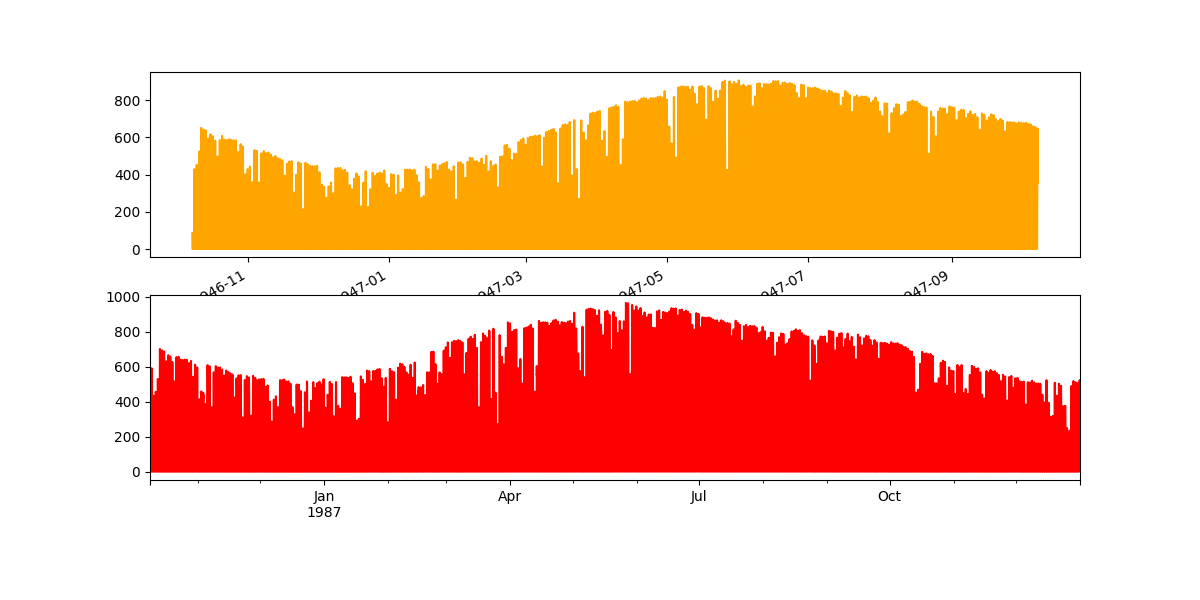

In [27]:
# Plot the SW radiation components
fig, ax = plt.subplots(2,1,figsize=(12, 6))
swdn_combined.loc[:,'swdn_total'].plot(ax=ax[0], color='orange', label='Total SW radiation (model)')
SWdown.loc['1986':'1987'].plot(ax=ax[1], color='red', label='SWdown forcing')

### Analysis: Snow

In [ ]:
# Plot snow and snow fraction in subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
model_surface_data.loc[plot_start_date:plot_end_date,'snow_depth'].plot(ax=ax1, label='Snow Depth', color='blue')
model_surface_data.loc[plot_start_date:plot_end_date,'snow_frac'].plot(ax=ax2, label='Snow Fraction', color='black')